## Final Capstone Project 24.1 — Technical Analysis and Final Report

**Author:** Sujit S Nair  
**Programme:** Emeritus — Machine Learning and Artificial Intelligence  
**Dataset:** CICIDS2017  
**Assignment:** Required Capstone Project 24.1 — Final Report  
**Project Type:** Supervised Machine Learning for Network Intrusion Detection

### Project Overview

This capstone investigates the application of supervised machine-learning algorithms to identifying malicious network traffic using the CICIDS2017 dataset.

The project includes exploratory data analysis, data cleaning, feature engineering, model development, stratified cross-validation, hyperparameter optimization, comparative performance evaluation and recommendations for further research.

The objective is to assess whether machine-learning techniques can support intrusion-detection decision-making in security-sensitive communication environments.


## 1. Research Question and Project Background

Can supervised machine-learning models distinguish benign and malicious CICIDS2017 network flows? The primary comparison metric is **attack-class F1-score**, balancing missed attacks and false alerts. Recall and precision are also reported separately. The data represent historical traffic flows; these results are not a production-readiness assessment.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Import Required Libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

## 2. Load the Dataset

Requires the eight official CICIDS2017 CSV files under the Google Drive path in the code cell below. The mounted Drive is session-specific; reconnect before a new run.


In [3]:
# ============================================
# Load and Merge CICIDS2017 Dataset
# ============================================
import pandas as pd
import glob
import os

# Folder containing all CSV files

data_path = "/content/drive/MyDrive/CICIDS2017_Capstone/MachineLearningCSV/MachineLearningCVE/*.csv"


# Read all CSV files
files = glob.glob(data_path)

print("Number of files found:", len(files))

# Load and combine
df = pd.concat(
    [pd.read_csv(file, low_memory=False) for file in files],
    ignore_index=True
)

print("Dataset Loaded Successfully")
print("Shape:", df.shape)

Number of files found: 8
Dataset Loaded Successfully
Shape: (2830743, 79)


## 3. Data Quality and Cleaning

The quality check measures missing entries, infinite values and duplicate rows before processing. Cleaning removes duplicate and incomplete rows and maps traffic labels to 0 (benign) and 1 (attack).


In [4]:

# Capstone 24.1 - Initial Data Quality Verification

import numpy as np
import pandas as pd

print("DATASET QUALITY REPORT")
print("-" * 45)

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

print("Missing values:", df.isna().sum().sum())
print("Duplicate records:", df.duplicated().sum())

numeric_data = df.select_dtypes(include=np.number)
print("Infinite numeric values:",
      np.isinf(numeric_data.to_numpy()).sum())

df.columns = df.columns.str.strip()

if "Label" in df.columns:
    print("\nTraffic class distribution:")
    print(df["Label"].astype(str).str.strip().value_counts())
else:
    print("Label column not found")


DATASET QUALITY REPORT
---------------------------------------------
Total records: 2830743
Total columns: 79
Missing values: 1358
Duplicate records: 308381
Infinite numeric values: 4376

Traffic class distribution:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [5]:

# Capstone 24.1 - Data Cleaning

import numpy as np
import pandas as pd

# Preserve original data
df_clean = df.copy()

# Standardize feature names and labels
df_clean.columns = df_clean.columns.str.strip()
df_clean["Label"] = df_clean["Label"].astype(str).str.strip()

# Replace infinite numeric values with missing values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove duplicate rows
df_clean.drop_duplicates(inplace=True)

# Remove records with missing values
df_clean.dropna(inplace=True)

# Define target for binary classification
# 0 = Benign, 1 = Attack
df_clean["AttackBinary"] = (
    df_clean["Label"].str.upper() != "BENIGN"
).astype(int)

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Removed records:", len(df) - len(df_clean))

print("\nBinary class distribution:")
print(df_clean["AttackBinary"].value_counts())

print("\nRemaining missing values:",
      df_clean.isna().sum().sum())


Original records: 2830743
Cleaned records: 2520798
Removed records: 309945

Binary class distribution:
AttackBinary
0    2095057
1     425741
Name: count, dtype: int64

Remaining missing values: 0


## 4. Exploratory Data Analysis

Visualize the imbalance between benign and malicious traffic, the main labeled attack categories, selected correlations and extreme numeric values. The plots below use the cleaned dataset, with sampling for resource-intensive plots.


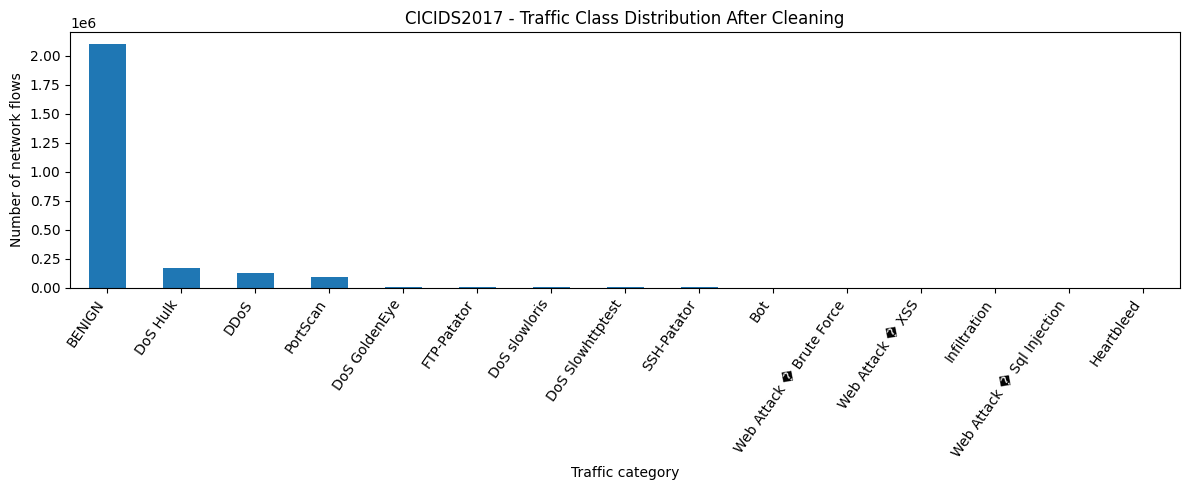

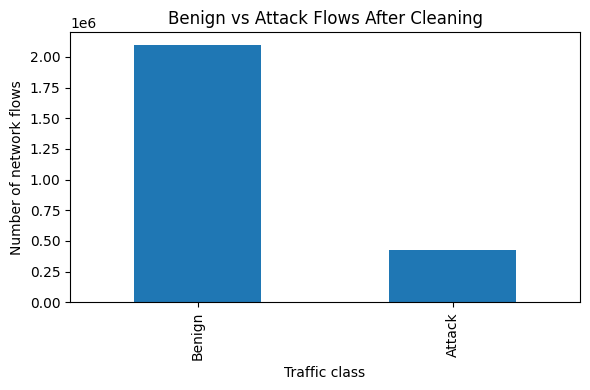

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Categorical distribution, both attack type and binary target
fig, ax = plt.subplots(figsize=(12, 5))
df_clean["Label"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("CICIDS2017 - Traffic Class Distribution After Cleaning")
ax.set_xlabel("Traffic category")
ax.set_ylabel("Number of network flows")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
df_clean["AttackBinary"].map({0:"Benign", 1:"Attack"}).value_counts().plot(kind="bar", ax=ax)
ax.set_title("Benign vs Attack Flows After Cleaning")
ax.set_xlabel("Traffic class")
ax.set_ylabel("Number of network flows")
plt.tight_layout()
plt.show()


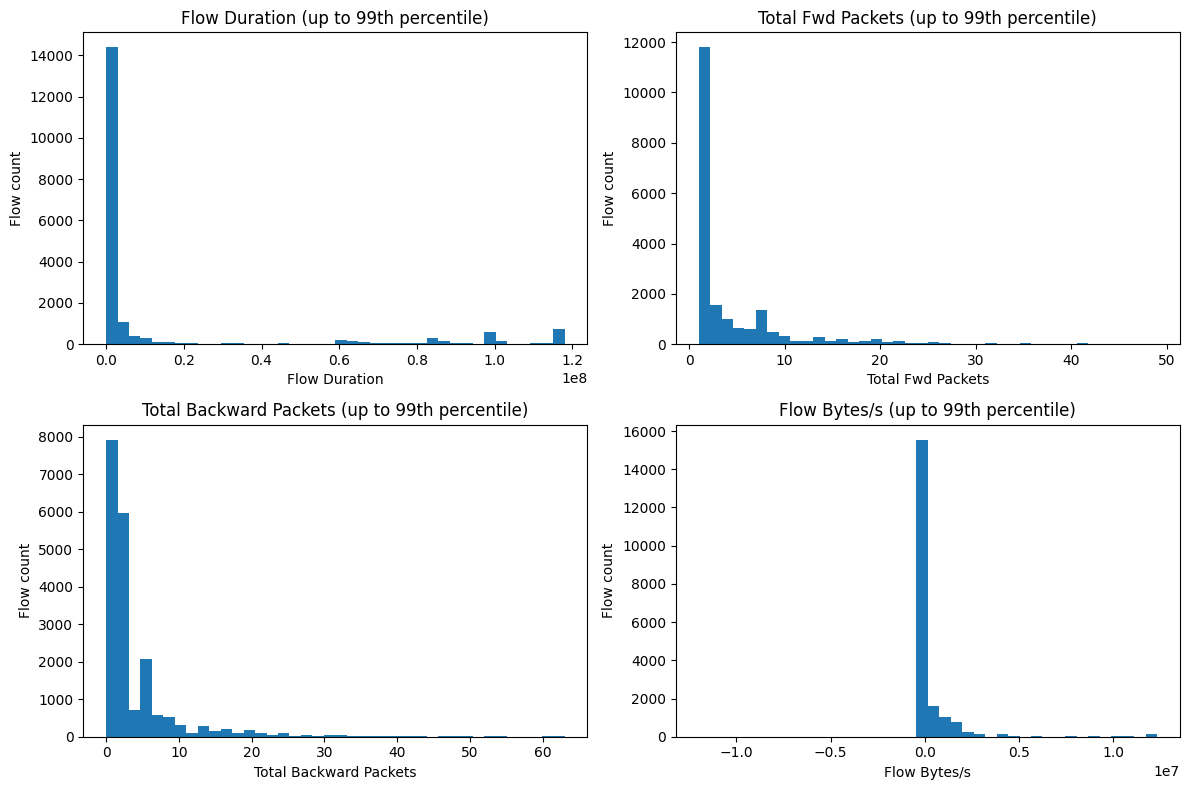

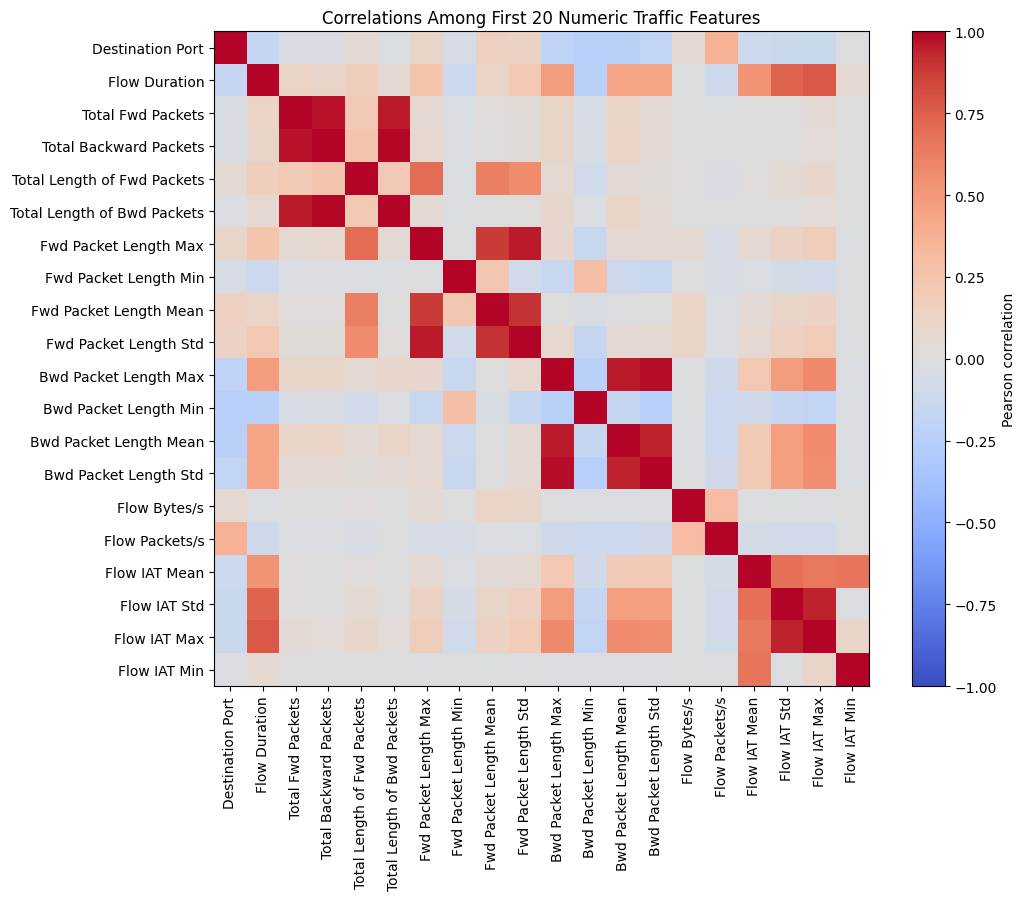

In [7]:
# Selected continuous features, represented by a 20,000-row reproducible sample
selected_features = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Bytes/s"]
eda_sample = df_clean.sample(n=min(20000, len(df_clean)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.ravel(), selected_features):
    values = pd.to_numeric(eda_sample[feature], errors="coerce").dropna()
    # High outliers are retained in the underlying dataset; plot clipped at the 99th percentile for readability.
    cutoff = values.quantile(0.99)
    ax.hist(values[values <= cutoff], bins=40)
    ax.set_title(f"{feature} (up to 99th percentile)")
    ax.set_xlabel(feature)
    ax.set_ylabel("Flow count")
plt.tight_layout()
plt.show()

numeric_features = df_clean.select_dtypes(include="number").drop(columns=["AttackBinary"], errors="ignore")
feature_names = numeric_features.columns[:20].tolist()
corr = eda_sample[feature_names].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(feature_names)), feature_names, rotation=90)
ax.set_yticks(range(len(feature_names)), feature_names)
ax.set_title("Correlations Among First 20 Numeric Traffic Features")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()


## 5. Stratified Modeling Sample and Holdout Split

A reproducible 100,000-flow stratified sample retains the cleaned class proportions, with 80% for training and 20% for testing. This random split can still overestimate generalization if related flows cross partitions; evaluate on separate days or networks in follow-up work.


In [8]:

# Capstone 24.1 - Training and Testing Data Preparation

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Stratified sample for efficient model comparison
sample_size = 100000

df_sample = (
    df_clean.groupby("AttackBinary", group_keys=False)
    .sample(
        frac=min(1.0, sample_size / len(df_clean)),
        random_state=42
    )
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# Separate predictive features and target
X = df_sample.drop(
    columns=["Label", "Attack", "AttackBinary"],
    errors="ignore"
)

y = df_sample["AttackBinary"]

# Convert features to numeric values
X = X.apply(pd.to_numeric, errors="coerce")

# Divide into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Sample records:", len(df_sample))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nNumber of predictive features:", X.shape[1])


Sample records: 100000
Training records: 80000
Testing records: 20000

Training class distribution:
AttackBinary
0    66489
1    13511
Name: count, dtype: int64

Testing class distribution:
AttackBinary
0    16622
1     3378
Name: count, dtype: int64

Number of predictive features: 78


## 6. Candidate Models and Holdout Test Evaluation

Compare Logistic Regression, Decision Tree and Random Forest using consistent partitions and attack-positive metrics. Pipelines fit imputation and scaling, where needed, from training data.


In [9]:

# Capstone 24.1 - Logistic Regression Model
# Binary intrusion detection: 0 = Benign, 1 = Attack

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create a leakage-safe modeling pipeline
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train only on the training dataset
logistic_model.fit(X_train, y_train)

# Evaluate on the untouched testing dataset
lr_pred = logistic_model.predict(X_test)

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1 Score": f1_score(y_test, lr_pred, zero_division=0)
}

print("LOGISTIC REGRESSION RESULTS")
print(pd.DataFrame([lr_results]).to_string(index=False))

print("\nClassification Report:")
print(classification_report(
    y_test, lr_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


LOGISTIC REGRESSION RESULTS
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression   0.93445   0.731882 0.96566  0.832674

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.93      0.96     16622
      Attack       0.73      0.97      0.83      3378

    accuracy                           0.93     20000
   macro avg       0.86      0.95      0.90     20000
weighted avg       0.95      0.93      0.94     20000



In [10]:

# Capstone 24.1 - Decision Tree Classification
# Binary intrusion detection: 0 = Benign, 1 = Attack

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Decision Tree pipeline
decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on the same training set
decision_tree_model.fit(X_train, y_train)

# Evaluate on the same held-out test set
dt_pred = decision_tree_model.predict(X_test)

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Precision": precision_score(y_test, dt_pred, zero_division=0),
    "Recall": recall_score(y_test, dt_pred, zero_division=0),
    "F1 Score": f1_score(y_test, dt_pred, zero_division=0)
}

print("DECISION TREE RESULTS")
print(pd.DataFrame([dt_results]).to_string(index=False))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


DECISION TREE RESULTS
        Model  Accuracy  Precision   Recall  F1 Score
Decision Tree    0.9958   0.979058 0.996448  0.987676

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     16622
      Attack       0.98      1.00      0.99      3378

    accuracy                           1.00     20000
   macro avg       0.99      1.00      0.99     20000
weighted avg       1.00      1.00      1.00     20000



In [11]:

# Capstone 24.1 - Random Forest Classification
# 0 = Benign, 1 = Attack

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the same training records
random_forest_model.fit(X_train, y_train)

# Predict on the same held-out test set
rf_pred = random_forest_model.predict(X_test)

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_pred, zero_division=0)
}

print("RANDOM FOREST RESULTS")
print(pd.DataFrame([rf_results]).to_string(index=False))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


RANDOM FOREST RESULTS
        Model  Accuracy  Precision   Recall  F1 Score
Random Forest    0.9982   0.995846 0.993487  0.994665

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     16622
      Attack       1.00      0.99      0.99      3378

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



## 7. Three-Fold Stratified Cross-Validation

Cross-validation is applied only to the training partition. It measures stability across sampled folds without using the held-out test set for fitting.


In [ ]:

# Capstone 24.1 - Stratified Cross-Validation
# Evaluate all three models on training data only

import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

cv_results = []

for name, model in models.items():

    print(f"Cross-validating: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARISON")
display(cv_results_df.round(4))


Cross-validating: Logistic Regression
Cross-validating: Decision Tree
Cross-validating: Random Forest

CROSS-VALIDATION COMPARISON


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std
0,Logistic Regression,0.9414,0.7533,0.9708,0.8483,0.0031
1,Decision Tree,0.9960,0.9814,0.9950,0.9881,0.0009
2,Random Forest,0.9977,0.9955,0.9910,0.9932,0.0006


## 8. GridSearchCV Hyperparameter Selection

Eight combinations are searched over a 30,000-record stratified subset of the training data, using three-fold cross-validation and attack F1-score. The tuned CV result is not directly comparable to the CV score obtained from all 80,000 training records.


In [12]:

# Capstone 24.1 - Random Forest GridSearchCV
# Hyperparameter optimization on training data only

import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Reuse the same cross-validation approach
grid_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Use a stratified subset of training data for
# computationally manageable hyperparameter tuning
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=30000,
    stratify=y_train,
    random_state=42
)

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Eight parameter combinations
param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [15, 25],
    "classifier__min_samples_leaf": [1, 3]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=grid_cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_tune, y_tune)

print("\nGRID SEARCH RESULTS")
print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 6))

grid_results_df = pd.DataFrame(
    grid_search.cv_results_
)

display(
    grid_results_df[
        [
            "params",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").round(4)
)


Fitting 3 folds for each of 8 candidates, totalling 24 fits

GRID SEARCH RESULTS
Best parameters: {'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best CV F1-score: 0.989785


,params,mean_test_score,std_test_score,rank_test_score
1,"{'classifier__max_depth': 15, 'classifier__min...",0.9898,0.0012,1
0,"{'classifier__max_depth': 15, 'classifier__min...",0.9895,0.0018,2
5,"{'classifier__max_depth': 25, 'classifier__min...",0.9894,0.0010,3
4,"{'classifier__max_depth': 25, 'classifier__min...",0.9893,0.0009,4
7,"{'classifier__max_depth': 25, 'classifier__min...",0.9892,0.0014,5
3,"{'classifier__max_depth': 15, 'classifier__min...",0.9892,0.0017,6
6,"{'classifier__max_depth': 25, 'classifier__min...",0.9887,0.0013,7
2,"{'classifier__max_depth': 15, 'classifier__min...",0.9882,0.0021,8


## 9. Refit and Evaluate Selected Model

The grid-selected configuration is refitted on all 80,000 training records and evaluated on the 20,000-record holdout set. This is a retrospective evaluation, not a prospective operational test.


In [13]:

# Capstone 24.1 - Optimized Random Forest Evaluation

import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Apply the best GridSearchCV configuration
# to the complete 80,000-record training set
optimized_rf = clone(grid_search.best_estimator_)

optimized_rf.fit(X_train, y_train)

# Evaluate on the held-out 20,000-record test set
optimized_pred = optimized_rf.predict(X_test)

optimized_results = {
    "Model": "Optimized Random Forest",
    "Accuracy": accuracy_score(y_test, optimized_pred),
    "Precision": precision_score(
        y_test, optimized_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, optimized_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, optimized_pred, zero_division=0
    )
}

print("OPTIMIZED RANDOM FOREST RESULTS")
display(pd.DataFrame([optimized_results]).round(6))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    optimized_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, optimized_pred))


OPTIMIZED RANDOM FOREST RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Optimized Random Forest,0.99815,0.995844,0.993191,0.994516



CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     16622
      Attack       1.00      0.99      0.99      3378

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000


CONFUSION MATRIX
[[16608    14]
 [   23  3355]]


## 10. Comparative Visualizations

Model comparison and error distributions provide complementary insight into false alarms and missed attacks.


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9344,0.7319,0.9657,0.8327
1,Decision Tree,0.9958,0.9791,0.9964,0.9877
2,Random Forest,0.9982,0.9958,0.9935,0.9947
3,Optimized Random Forest,0.9982,0.9958,0.9932,0.9945


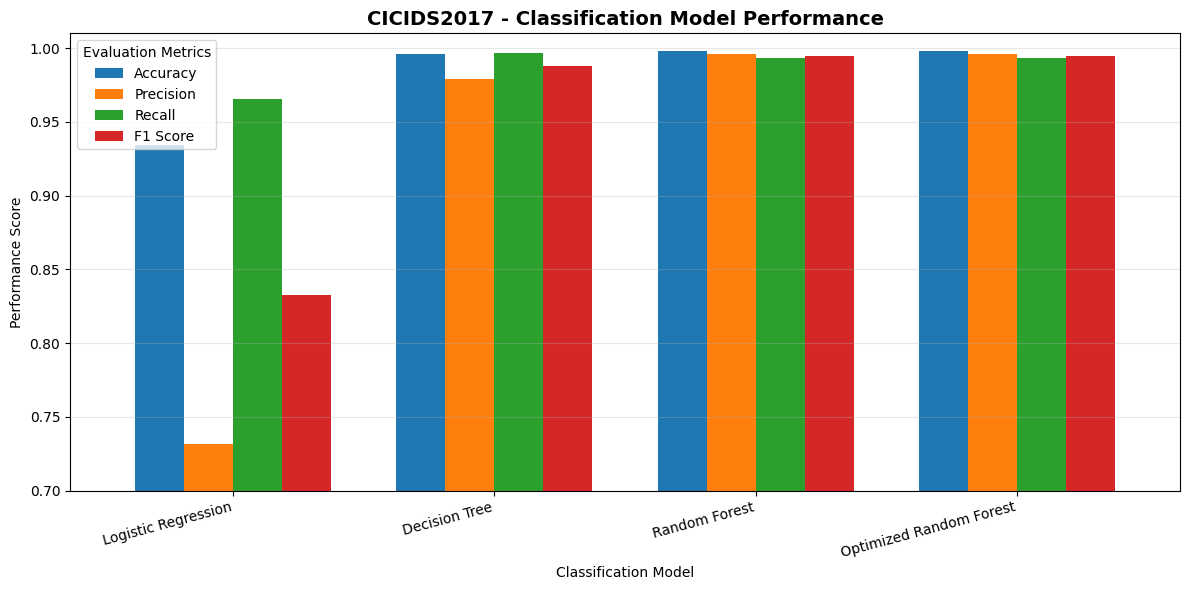

In [15]:

# Capstone 24.1 - Final Model Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

# Combine previously calculated model results
model_comparison = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    optimized_results
])

print("FINAL MODEL COMPARISON")
display(model_comparison.round(4))

# Visualize test-set performance
plot_data = model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "CICIDS2017 - Classification Model Performance",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Classification Model")
ax.set_ylabel("Performance Score")
ax.set_ylim(0.70, 1.01)

plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


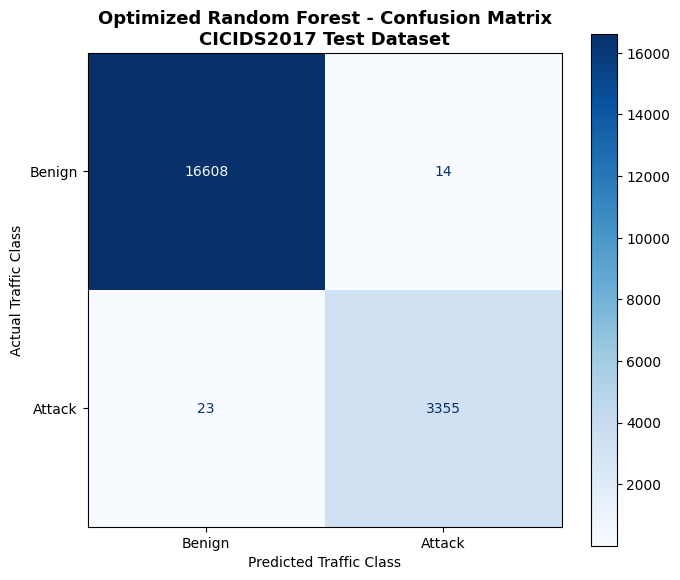

In [16]:

# Capstone 24.1 - Optimized Random Forest Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    optimized_pred,
    display_labels=["Benign", "Attack"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Optimized Random Forest - Confusion Matrix\nCICIDS2017 Test Dataset",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Predicted Traffic Class")
ax.set_ylabel("Actual Traffic Class")

plt.tight_layout()
plt.show()


## 11. Feature Importance of Optimized Random Forest

The following is model-specific impurity-based feature importance, which indicates what the fitted forest used for classification, not causal importance. Correlated variables can share importance.


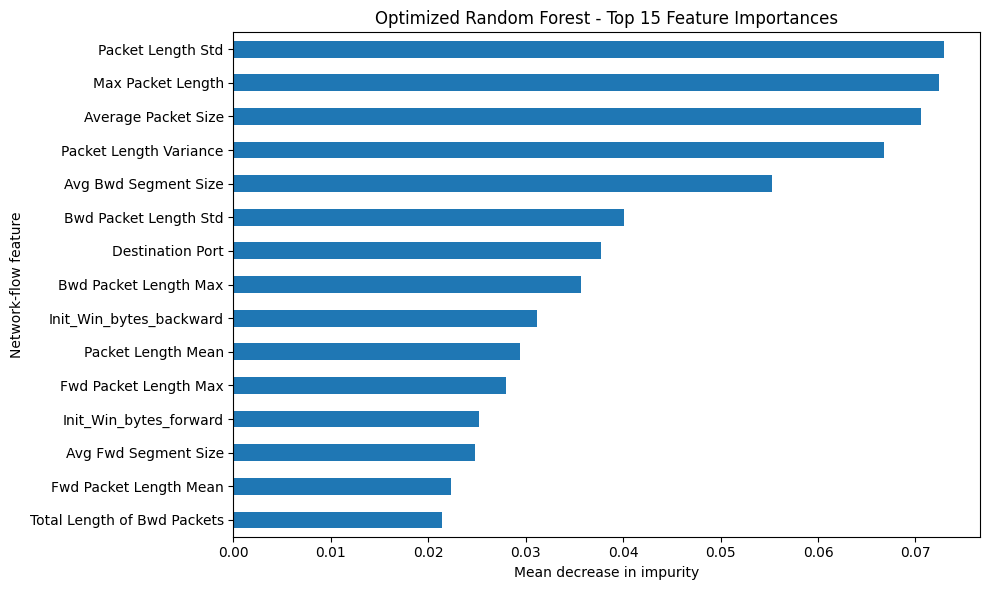

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

forest = optimized_rf.named_steps["classifier"]
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False).head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
importance.plot(kind="barh", ax=ax)
ax.set_title("Optimized Random Forest - Top 15 Feature Importances")
ax.set_xlabel("Mean decrease in impurity")
ax.set_ylabel("Network-flow feature")
plt.tight_layout()
plt.show()


## 12. Final Technical Findings and Recommendations

### 12.1 Project Objective
This project evaluates supervised machine-learning algorithms for detecting malicious network traffic using CICIDS2017.

### 12.2 Dataset and Data Preparation
The original dataset contained 2,830,743 records and 79 columns. Data-quality checks identified 1,358 missing values, 4,376 infinite values and 308,381 duplicate records.

After cleaning, 2,520,798 records remained, including 2,095,057 benign and 425,741 attack records.

A stratified sample of 100,000 records was divided into 80,000 training and 20,000 testing records.

### 12.3 Final Model Comparison

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 93.44% | 73.19% | 96.57% | 83.27% |
| Decision Tree | 99.58% | 97.91% | 99.64% | 98.77% |
| Random Forest | 99.82% | 99.58% | 99.35% | 99.47% |
| Optimized Random Forest | 99.82% | 99.58% | 99.32% | 99.45% |

The original Random Forest achieved the highest test F1-score, while Decision Tree achieved the highest attack recall.

### 12.4 Cross-Validation and GridSearchCV
Three-fold stratified cross-validation was performed on Logistic Regression, Decision Tree and Random Forest.

Random Forest achieved approximately 99.32% cross-validation F1-score on the 80,000-record training partition.

GridSearchCV evaluated eight parameter combinations over three folds using a 30,000-record training subset.

Best parameters:
- n_estimators: 100
- max_depth: 15
- min_samples_leaf: 1

Best GridSearchCV F1-score: 98.9785%.

Hyperparameter tuning did not improve the held-out test F1-score compared with the original Random Forest.

### 12.5 Optimized Random Forest Confusion Matrix
The optimized Random Forest correctly classified 19,963 of 20,000 test records.

- True negatives: 16,608
- False positives: 14
- False negatives: 23
- True positives: 3,355

The model detected 3,355 of 3,378 attack records and missed 23 attacks.

### 12.6 Key Findings
1. Supervised machine-learning models performed strongly on the evaluated historical CICIDS2017 data.
2. Random Forest achieved the highest overall test F1-score.
3. Decision Tree achieved the highest attack recall.
4. GridSearchCV identified a competitive configuration but did not improve test F1-score.
5. False alarms and missed attacks must be considered when assessing operational usefulness.

### 12.7 Limitations
Randomly partitioned historical traffic may contain closely related flows across training and testing sets. This could overestimate real-world generalization.

The dataset does not represent all modern attacks or live defence communication environments. Binary classification also does not establish performance on individual attack types.

### 12.8 Recommendations
1. Validate models on independent and more recent datasets.
2. Evaluate performance separately for individual attack categories.
3. Investigate false positives and missed attacks.
4. Test time-based or group-based data splitting.
5. Evaluate prediction speed, scalability and robustness.
6. Consider human-supervised deployment only after additional validation.

### 12.9 Conclusion
The CICIDS2017 experiments demonstrate the potential of supervised machine learning to support network intrusion detection.

The original Random Forest achieved the highest test F1-score of approximately 99.47%, while Decision Tree achieved the highest attack recall of approximately 99.64%.

Further independent validation is required before considering deployment in operational security environments.

## 13. Reproducibility Notes

Run cells in order from a fresh Colab runtime with the original eight CSV files mounted through Google Drive. The dataset is large and may require a high-memory runtime. Dataset path is Google-Drive-specific. The `requirements.txt` file in the GitHub repository should specify compatible versions of Python, pandas, NumPy, scikit-learn and Matplotlib. The random seed for sampling and model fitting is 42. The full historical dataset was deduplicated and cleaned before the random-split comparison.
